# Naiwny klasyfikator Bayesa

Rozważymy klasyczny problem klasyfikacji odmian irysów na podstawie cech płatków. Jest to klasyczny już problem, często wykorzystywany przy porównywaniu różnych technik klasyfikacji. Więcej o pochodzeniu tych danych i problemie można przeczytać tu: [Iris_flower_data](https://en.wikipedia.org/wiki/Iris_flower_data_set)

W tym notatniku użyjemy naiwnego klasyfikatora Bayesa. Kod napiszemy w oparciu o implementacje klasyfikatora Bayesa z biblioteki [scikit-learn](http://scikit-learn.org/stable/about.html#citing-scikit-learn)

Zaczerpniemy stamtąd:
* obiekt klasyfikatora [GaussianNB](https://scikit-learn.org/stable/modules/generated/sklearn.naive_bayes.GaussianNB.html),
* zbiór danych,
* funkcje do oceny jakości klasyfikacji

### Przygotowanie środowiska programistycznego

In [122]:
import numpy as np
from termcolor import colored

from sklearn import datasets
from sklearn.naive_bayes import GaussianNB
import sklearn.metrics

from sklearn.model_selection import StratifiedKFold, train_test_split


from scipy.stats import multivariate_normal



import matplotlib.pyplot as plt
from matplotlib import colormaps as pltc
import seaborn as sns

import pandas as pd

## Wczytanie danych do analizy

Zbiór danych ``Iris`` jest dostępny w bibliotece sklearn jako jeden z wielu standardowych zbiorów [testowych](https://scikit-learn.org/stable/datasets/toy_dataset.html).

In [123]:
#Wczytywanie danych
iris = datasets.load_iris()

#Wypisywanie zawartości wczytanego obiektu
print(dir(iris))

['DESCR', 'data', 'data_module', 'feature_names', 'filename', 'frame', 'target', 'target_names']


## Analiza zawartości danych

**Proszę** wypisać:

* nazwy gatunków,
* kodowanie gatunków, czyli liczby przypisane do nazw gatunków ```target```,
* nazwy zmiennych opisujących gatunki ```feature_names```,

**Wskazówka**: informacje o zbiorze uzyskujemy traktując go jak słownik:
```Python
print(iris['filename'])
```

In [124]:
print(iris['target_names'])
print(iris['target'])
print(iris['feature_names'])
print(iris['DESCR'])

['setosa' 'versicolor' 'virginica']
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2]
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
.. _iris_dataset:

Iris plants dataset
--------------------

**Data Set Characteristics:**

:Number of Instances: 150 (50 in each of three classes)
:Number of Attributes: 4 numeric, predictive attributes and the class
:Attribute Information:
    - sepal length in cm
    - sepal width in cm
    - petal length in cm
    - petal width in cm
    - class:
            - Iris-Setosa
            - Iris-Versicolour
            - Iris-Virginica

:Summary Statistics:

============== ==== ==== ======= ===== ====================
                Min  Max   Mean    SD   Class Correla

## Przepisane danych do obiektu Pandas DataFrame

**Proszę** utworzyć obiekt DataFrame zawierający własności ("features") oraz etykiety ("label")
* przypisać poprawne nazwy kolumn: ```columns=iris.feature_name```,
* dodać do obiektu DataFrame kolumnę ```label``` zawierającą etykiety,
* wypisać własności przykładu o indeksie 5
* sprawdzić jaki gatunek odpowiada wartości etykiety przykładu o indeksie 5.

**Wskazówka:** można skorzystać z funkcji DataFrame.loc(index)

Oczekiwany wynik:
```Python
sepal length (cm)    5.4
sepal width (cm)     3.9
petal length (cm)    1.7
petal width (cm)     0.4
label                0.0
Name: 5, dtype: float64
Gatunek przykładu o indeksie 5: setosa
```

In [125]:
df=pd.DataFrame(iris['data'],columns=iris.feature_names)
df['label']=iris['target']
df.iloc[5]
example_species=df['label'].iloc[5]
print(colored("Gatunek przykładu o indeksie 5:\n","blue"), example_species)

Gatunek przykładu o indeksie 5:
 0


## Analiza wizualna danych.

Pierwszy krok przy analizie danych z użyciem dowolnego algorytmu to ich inspekcja. Korzystając z metod klasy `DataFrame`.

**Proszę:**
* narysować jednowymiarowe histogramy dla wszystkich zmiennych (kolumn obiektu DataFrame)

In [126]:
...
pass

Naszym zadaniem jest rozdzielenie gatunków na podstawie własności. Poniższa komórka rysuje rozkłady (histogramy) własności w podziale na  gatunki.

**Proszę:**

* na podstawie histogramów proszę zidentyfikować cechy, które najlepiej odróżniają gatunki.

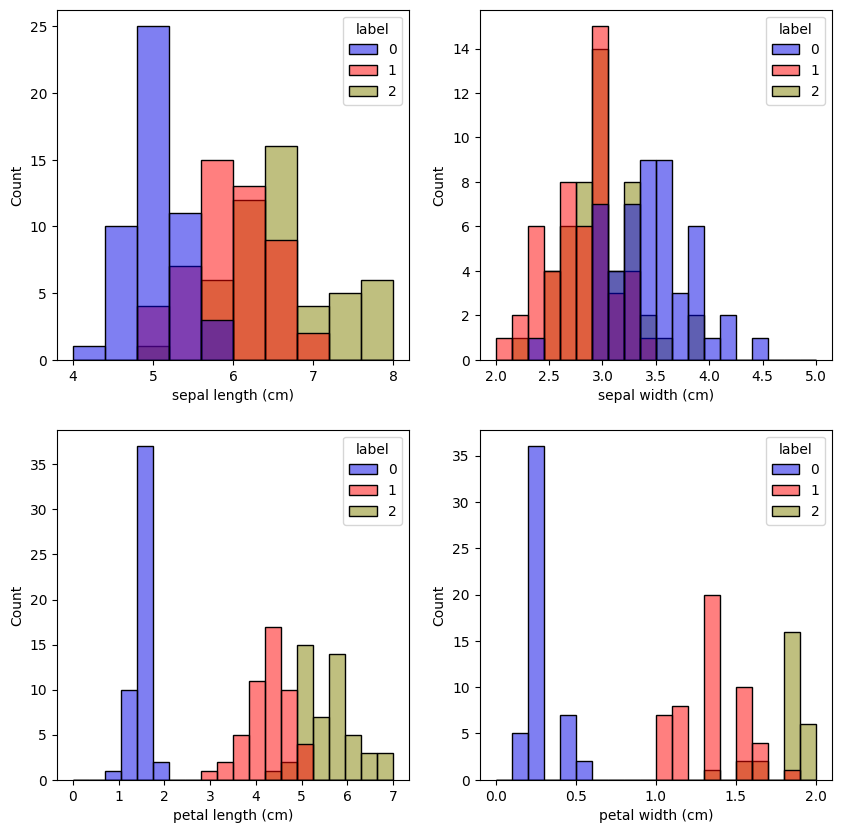

In [127]:
fig, axes = plt.subplots(2,2, figsize=(10,10))
color_map = {-1: (1, 1, 1), 0: (0, 0, .9), 1: (1, 0, 0), 2: (.5, .5, 0)}

sns.histplot(data=df, x="sepal length (cm)", hue="label", binrange=(4,8),palette=color_map, bins=10, ax=axes[0,0]);
sns.histplot(data=df, x="sepal width (cm)", hue="label", palette=color_map, binrange=(2,5), bins=20, ax=axes[0,1]);
sns.histplot(data=df, x="petal length (cm)", hue="label", palette=color_map, binrange=(0,7), bins=20, ax=axes[1,0]);
sns.histplot(data=df, x="petal width (cm)", hue="label", palette=color_map, binrange=(0,2), bins=20, ax=axes[1,1]);

## Wykres skrzypcowy ("violin plot")

Histogramy dla poszczególnych gatunków się nakładają częściowo. Inny sposób wizualizacji to wykres skrzypcowy (ang. "violin plot"). Poniższa komórka
rysuje wykresy skrzypcowe dla poszczególnych cech z podziałem na gatunki.

**Proszę:**

* na podstawie rysunków zidentyfikować cechy, które najlepiej odróżniają gatunki.

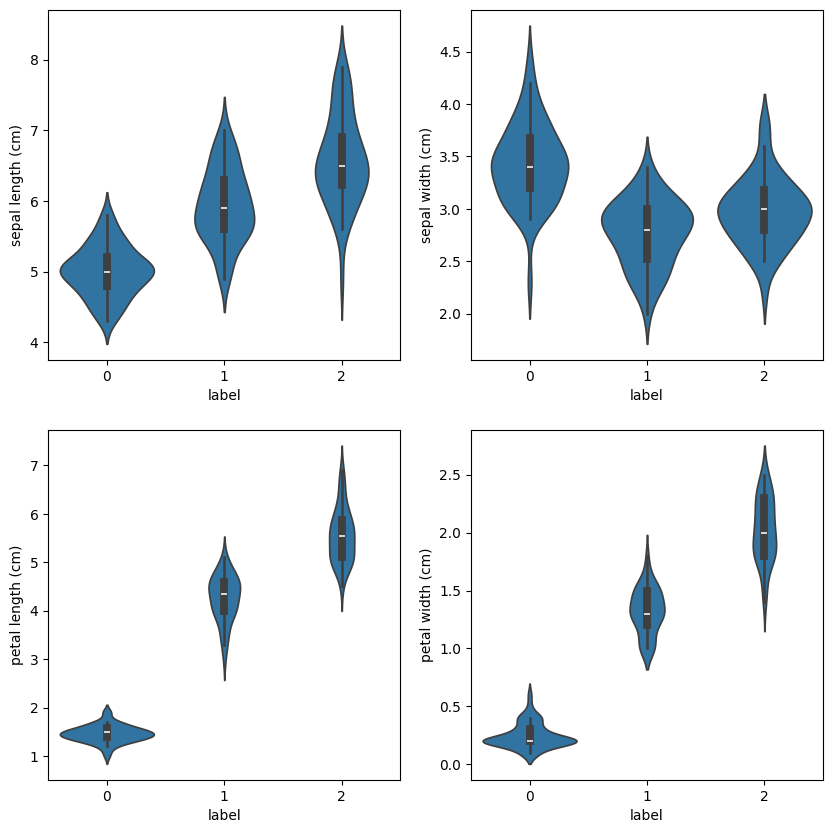

In [128]:
fig, axes = plt.subplots(2,2, figsize=(10,10))

for index, columnName in enumerate(df.columns[0:4]):
    sns.violinplot(data=df, x="label", y=columnName,ax=axes[(int)(index/2),index%2]);

## Analiza dwuwymiarowa

Rysunki narysowane do tej pory były jednowymiarowe. Kolejny krok to wizualna analiza korelacji między cechami. Korelację między cechami można zwizualizować na wiele sposobów. Poniższa komórka rysuje:

* macierz kowariancji między wszystkimi kolumnami danych włączając etykiety
* dwuwymiarowe rozkłady dla par cech

Więcej przykładów wizualizacji można znaleźć w dokumentacji: [link](https://seaborn.pydata.org/tutorial/axis_grids.html).

                   sepal length (cm)  sepal width (cm)  petal length (cm)  \
sepal length (cm)           1.000000         -0.117570           0.871754   
sepal width (cm)           -0.117570          1.000000          -0.428440   
petal length (cm)           0.871754         -0.428440           1.000000   
petal width (cm)            0.817941         -0.366126           0.962865   
label                       0.782561         -0.426658           0.949035   

                   petal width (cm)     label  
sepal length (cm)          0.817941  0.782561  
sepal width (cm)          -0.366126 -0.426658  
petal length (cm)          0.962865  0.949035  
petal width (cm)           1.000000  0.956547  
label                      0.956547  1.000000  


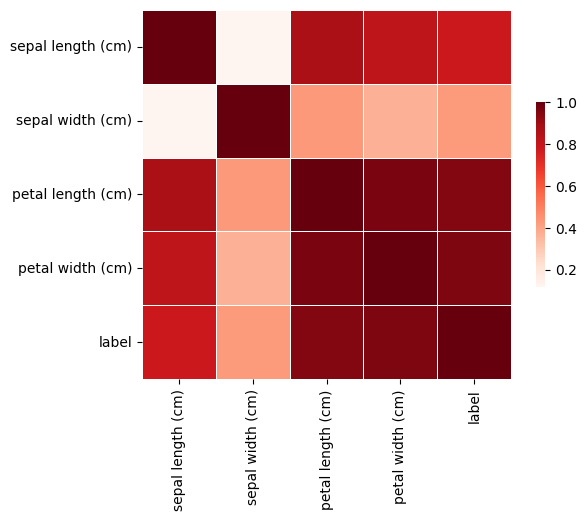

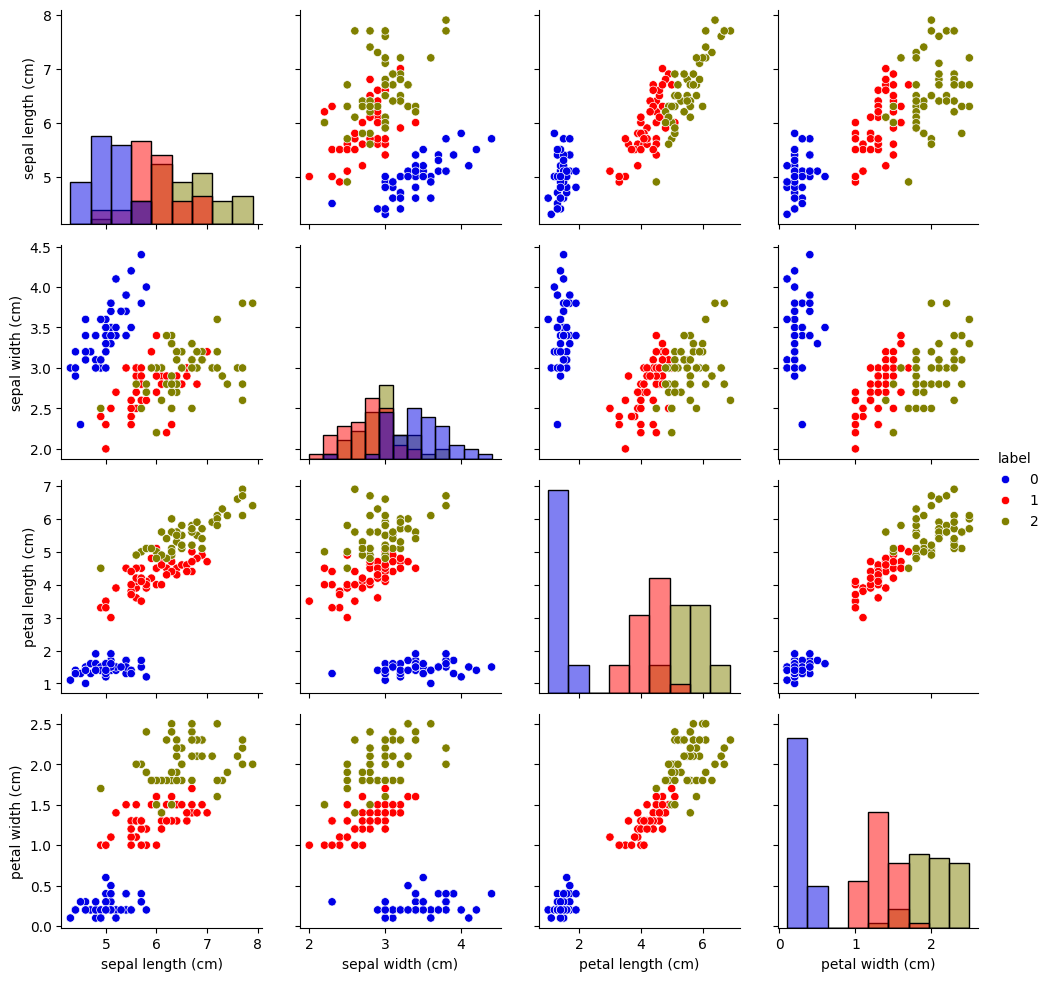

In [129]:
corelationMatrix = df.corr()
print(corelationMatrix)

cmap = sns.diverging_palette(230, 20, as_cmap=True)
sns.heatmap(abs(corelationMatrix), square=True, linewidths=.5, cbar_kws={"shrink": .5}, cmap='Reds');

graph = sns.PairGrid(df, hue="label", palette=color_map)
graph.map_diag(sns.histplot)
graph.map_offdiag(sns.scatterplot);
graph.add_legend();

## Przygotowanie danych wejściowych (ang. preprocessing)

Od tego momentu, aby ułatwić analizę wyniku działania modelu ograniczymy się do dwu cech - wtedy będzie można narysować podział na gatunki na płaszczyźnie.

Standardową procedurą obróbki danych przed utworzeniem modelu jest ich normalizacja, najlepiej do zakresu [-1,1] lub [0,1].
Znormalizujemy wartości cech według wzoru:

\begin{equation}
x_{norm} = \frac{x - \mu_{x}}{\sigma_{x}}
\end{equation}

**Proszę:**

* utworzyć nowy obiekt DataFrame ```df_normalized``` zawierający znormalizowane kolumny własności oraz etykiety:
* utworzyć obiekt DataFrame ```df_subset``` zawierający tylko wybrane cechy, oraz etykiety:
  
  ```Python
  ["sepal width (cm)","petal length (cm)", "label"]
  ```
<br></br>
* wypisać zawartość obiektów ```df_normalized``` i ```df_subset```. Czy widać efekt normalizacji w wartościach opisujących dane?

**Uwaga:** proszę nie normalizować wartości etykiet

In [130]:
lst=["sepal length (cm)","sepal width (cm)","petal length (cm)","petal width (cm)"]
df_normalized=pd.DataFrame()
for i in lst:
  df_normalized[i]=(df[i]-df[i].mean())/df[i].std()
df_normalized["label"]=df["label"]
df_subset=pd.DataFrame(df_normalized[['sepal width (cm)',"petal length (cm)"]])
df_subset["label"]=df["label"]
print(colored("Normalized dataset:","blue"))
print(df_normalized.describe())
print(colored("Normalized dataset with only two features:","blue"))
print(df_subset.describe())

Normalized dataset:
       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count       1.500000e+02      1.500000e+02       1.500000e+02   
mean       -5.210647e-16     -7.579123e-16      -2.842171e-16   
std         1.000000e+00      1.000000e+00       1.000000e+00   
min        -1.863780e+00     -2.425820e+00      -1.562342e+00   
25%        -8.976739e-01     -5.903951e-01      -1.222456e+00   
50%        -5.233076e-02     -1.315388e-01       3.353541e-01   
75%         6.722490e-01      5.567457e-01       7.602115e-01   
max         2.483699e+00      3.080455e+00       1.779869e+00   

       petal width (cm)       label  
count      1.500000e+02  150.000000  
mean      -3.789561e-16    1.000000  
std        1.000000e+00    0.819232  
min       -1.442245e+00    0.000000  
25%       -1.179859e+00    0.000000  
50%        1.320673e-01    1.000000  
75%        7.880307e-01    2.000000  
max        1.706379e+00    2.000000  
Normalized dataset with only two features:
       se

**Proszę:**
* narysować dwuwymiarowe rozkłady dla par cech dla znormalizowanych dla DataFrame z dwiema cechami.

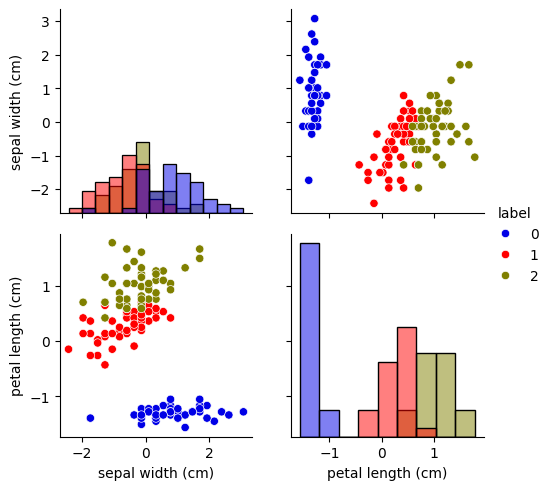

In [131]:
graph1 = sns.PairGrid(df_subset, hue="label", palette=color_map)
graph1.map_diag(sns.histplot)
graph1.map_offdiag(sns.scatterplot);
graph1.add_legend();

## Definicja i trening klasyfikatora

W tym notatniku użyjemy klasyfikatora [naive bayes](https://scikit-learn.org/stable/modules/naive_bayes.html) w wersji gausowskiej.

**Proszę:**

* utworzyć obiekt ```gnb``` klasy [GaussianNB](https://scikit-learn.org/stable/modules/generated/sklearn.naive_bayes.GaussianNB.html)
* przeprowadzić trening z użyciem funkcji ```fit()```

In [132]:
gnb=GaussianNB()
X=df_subset.iloc[:,0:2]
Y=df_subset["label"]
gnb.fit(X,Y)
print(colored("Accuracy on train dataset: ","blue"), gnb.score(X,Y))

Accuracy on train dataset:  0.92


**Proszę:**


* wypisać wartości parametrów modelu: średnie i odchylenia standardowe rozkładów Gaussa. Średnie znajdują się w polu  ```gnb.theta_```, a wariancje
  w ```gnb.var_```
* wypisać średnie i odchylenia standardowe rozkładów cech w podziale na gatunki obliczone z danych
* porównać uzyskane wartości. Czy liczby są zgodne z oczekiwaniami?

**Wskazówka:** proszę skorzystać z grupowania danych: `DataFrame.groupby()`.

Oczekiwany wynik dla parametrów z modelu:
```Python
Mean:
 [[ 0.85041372 -1.30063009]
 [-0.65922358  0.28437121]
 [-0.19119013  1.01625888]]
Sigma:
 [[0.86093968 0.09738785]
 [0.71270594 0.26351816]
 [0.73246175 0.30949324]]
```

In [133]:
print(gnb.theta_)
print(np.sqrt(gnb.var_))


[[ 0.85041372 -1.30063009]
 [-0.65922358  0.28437121]
 [-0.19119013  1.01625888]]
[[0.86093968 0.09738785]
 [0.71270594 0.26351816]
 [0.73246175 0.30949324]]


### Porównanie dopasowanych rozkładów z danymi.
Komórki poniżej zawierają funkcje:

* ```plot_2d_gaussian(mean, covariance, axis)``` - funkcja która rysuje dwuwymiarowy rozkład Gaussa o średniej ```mean``` i diagonalnej macierzy kowariancji ```np.diag(cov)``` na obszarze danym przez obiekt ```axis```,
* ```plot_2d_divison(model, axis)``` - funkcja która rysuje kontury podziału na klasy na podstawie modelu ```model``` na obszarze danym przez obiekt ```axis```.

In [134]:
def plot_2d_gaussian(mean, cov, axis):
    xx, yy = np.mgrid[-3:3:0.1, -3:2:0.1]
    pos = np.dstack((xx, yy))
    zz = multivariate_normal.pdf(pos, mean=mean, cov=np.diag(cov))
    axis.contour(xx, yy, zz, 10)

def plot_2d_divison(model, axis):
    xx, yy = np.mgrid[-4:4:0.01, -4:4:0.01]
    pos = np.c_[xx.ravel(), yy.ravel()]
    zz = model.predict(pos)
    zz = np.reshape(zz, xx.shape)
    axis.contour(xx, yy, zz, cmap=plt.cm.Paired)

Poniższa komórka rysuje:

* dwuwymiarowy rozkład danych dla analizowanego zbioru. Punkty są pokolorowane według przynależności do gatunku,
* funkcja ```plot_2d_gaussian(mean, covariance, axis)``` rysuje na tym samym rysunku poziomnice rozkładów Gaussa modelu ```gnb = GaussianNB()```.

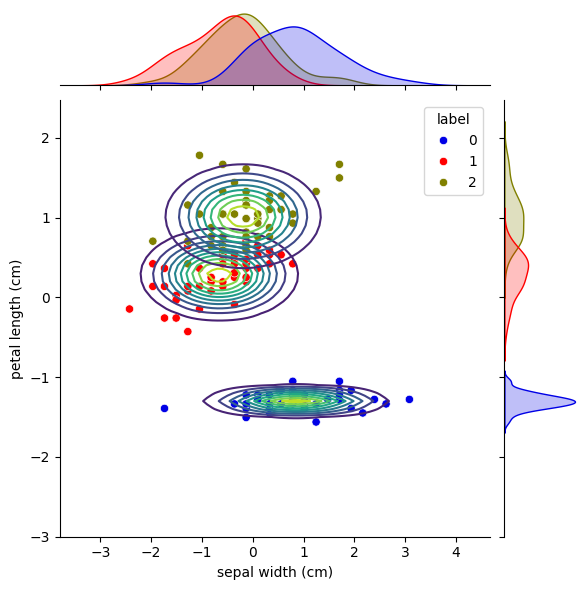

In [135]:
graph = sns.jointplot(x="sepal width (cm)", y="petal length (cm)", data=df_subset, hue="label", palette=color_map)

for classNumber in range(0,3):
    plot_2d_gaussian(mean=gnb.theta_[classNumber], cov=np.diag(gnb.var_[classNumber]), axis=graph.ax_joint)

**Proszę:**

* korzystając z funkcji ```sns.jointplot``` narysować dwuwymiarowy rozkład danych dla analizowanego zbioru. Punkty powinny być pokolorowane według przynależności do gatunku,
* korzystając z funkcji ```plot_2d_divison(model, axis)``` nanieść granice podziału na gatunki.

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but GaussianNB was fitted with feature names
  warnings.warn(


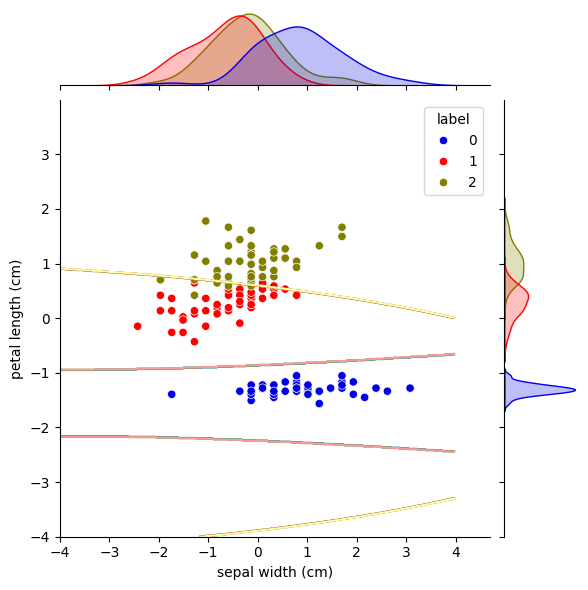

In [136]:
graph = sns.jointplot(x="sepal width (cm)", y="petal length (cm)", data=df_subset, hue="label", palette=color_map)
plot_2d_divison(gnb, graph.ax_joint)

## Analiza jakości modelu
Korzystając z walidacji krzyżowej przeprowadzimy analizę miar jakości modeli. Skorzystamy z funkcji opisanych w rozdziale [Model evaluation](http://scikit-learn.org/stable/modules/model_evaluation.html) dokumentacji pakietu scikit-learn.

**Proszę:**

* przejrzeć listę dostępnych metryk i upewnić się, co dokładnie zwracają poszczególne funkcje,
* porównać definicje z scikit-learn z definicjami z [wykładu](https://brain.fuw.edu.pl/edu/index.php/Uczenie_maszynowe_i_sztuczne_sieci_neuronowe/Wyk%C5%82ad_Ocena_jako%C5%9Bci_klasyfikacji),
* uzupełnić kod funkcji ```printScores(model, X, Y)```, która przyjmuje ```model```, cechy ```X``` oraz etykiety ```Y``` i wypisuje
  raport o klasyfikacji oraz macierz pomyłek
  
Oczekiwany wynik:
```Python
Classification report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       0.85      0.92      0.88        50
           2       0.91      0.84      0.87        50

    accuracy                           0.92       150
   macro avg       0.92      0.92      0.92       150
weighted avg       0.92      0.92      0.92       150

Confusion matrix:
[[50  0  0]
 [ 0 46  4]
 [ 0  8 42]]
```

In [137]:
def printScores(model, X, Y):
    print("Classification report:")
    print(classification_report(Y,model.predict(X)))


printScores(gnb, X, Y)

print(confusion_matrix(Y,gnb.predict(X)))

Classification report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       0.85      0.92      0.88        50
           2       0.91      0.84      0.88        50

    accuracy                           0.92       150
   macro avg       0.92      0.92      0.92       150
weighted avg       0.92      0.92      0.92       150

[[50  0  0]
 [ 0 46  4]
 [ 0  8 42]]


## Porównanie  modeli

**Proszę:**

Stworzyć trzy klasyfikatory:

* korzystający z cech ```["sepal width (cm)","petal length (cm)"]``` (nasz dotychczasowy model): ```gnb_features_1_2```
* korzystający tylko z cech ```["sepal length (cm)","sepal width (cm)"]```: ```gnb_features_0_1```
* korzystający ze wszystkich czterech cech: ```gnb_features_all```
* dla każdego z modeli wypisać wartości miar jakości i na ich podstawie stwierdzić który model jest najlepszy

**Pytanie:** Czy powyższe kryterium wyboru najlepszego modelu jest w pełni poprawne?

In [138]:
def train_model(X_test, X_train, y_train):
    # Inicjalizacja klasy modelu
    model=GaussianNB()
    # Dopasowanie modelu do danych treningowych
    model.fit(X=X_train,y=y_train)
    #Predykcja na zbiorze testowym
    y_prob = model.predict_proba(X_test)
    return y_prob

def get_scores(y_true, y_prob):
    #Przekształcenie prawdopodobieństw na etykiety klas
    lbls=np.argmax(y_prob,axis=1)
    #Obliczenie wartości miar jakości
    av="weighted"
    metrics_dict = {"PPV":sklearn.metrics.precision_score(y_true,lbls, average=av),
                    "ACC":sklearn.metrics.accuracy_score(y_true,lbls),
                    "TPR":sklearn.metrics.recall_score(y_true,lbls,average=av),
                    "F1":sklearn.metrics.f1_score(y_true,lbls,average=av)}
    return metrics_dict

def cross_val_metrics(df, n_splits=5):
    # Wydzielenie danych wejściowych i wyjściowych z df
    X = df[['sepal width (cm)',"petal length (cm)"]].values
    y = df["label"].values
    metrics_dict_cv = {'PPV': [], "ACC":[], 'TPR': [], 'F1': [],}
    # Inicjalizacja StratifiedKFold i pętla po podziałach
    skf=StratifiedKFold(n_splits=n_splits)
    skf.get_n_splits()
    for i, (train_index, test_index) in enumerate(skf.split(X, y)):
      y_prob=train_model(df.iloc[test_index][['sepal width (cm)',"petal length (cm)"]],df.iloc[train_index][['sepal width (cm)',"petal length (cm)"]],df.iloc[train_index]["label"])
      dict1=get_scores(df.iloc[test_index]["label"],y_prob)
      for key in dict1:
        metrics_dict_cv[key].append(dict1[key])
    # Wypisanie średnich i odchyleń standardowych dla każdej miary
    for key in metrics_dict_cv.keys():
        mean_val = np.mean(metrics_dict_cv[key])
        std_val = np.std(metrics_dict_cv[key])
        print(f"{key}: {mean_val:.3f} ± {std_val:.3f}")

print("krzyżowa:")
cross_val_metrics(df_subset)
print("\n GNB dla wszystkich danych:")
gnb1=GaussianNB()
X1=df_normalized.iloc[:,0:4]
Y1=df_normalized["label"]
gnb1.fit(X1,Y1)
printScores(gnb1, X1, Y1)
print(confusion_matrix(Y1,gnb1.predict(X1)))

krzyżowa:
PPV: 0.918 ± 0.040
ACC: 0.913 ± 0.040
TPR: 0.913 ± 0.040
F1: 0.913 ± 0.040

 GNB dla wszystkich danych:
Classification report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       0.94      0.94      0.94        50
           2       0.94      0.94      0.94        50

    accuracy                           0.96       150
   macro avg       0.96      0.96      0.96       150
weighted avg       0.96      0.96      0.96       150

[[50  0  0]
 [ 0 47  3]
 [ 0  3 47]]


## Analiza wpływu normalizacji danych.

**Proszę:**

* wytrenować model na wszystkich cechach, ale korzystając z oryginalnych danych - bez normalizacji wartości cech,
* wypisać wartości miar jakości dla uzyskanego modelu

**Pytanie:** Czy normalizacja wpływa na wydajność naszego modelu?

In [139]:
print(colored("Model using","blue"), "all", colored("features:", "blue"), "without normalisation")
...
pass

Model using all features: without normalisation


# Zadanie domowe

## Dekorelacja zmiennych.
Niektóre zmienne są silnie skorelowane - algorytm "naiwny" nie radzi sobie z tym dobrze.
Proszę wytrenować modele na następujących danych  normalizacji:

* zawierających dwie silnie skorelowane cechy:
```Python
["petal length (cm)","petal width (cm)"]
```
* zawierających ich zdekorelowane funkcje $x$ i $y$ będące sumą i różnicą skorelowanych zmiennych:
```Python
x = "petal length (cm)" + "petal width (cm)"
y = "petal length (cm)" - "petal width (cm)"
```
* proszę narysować dwuwymiarowe rozkłady dla zmiennych $x$ i $y$
* czy model używający zmiennych $x$ i $y$ jest lepszy/gorszy od modeli trenowanych wcześniej? Odpowiedź uzasadnij.

In [140]:
...
pass